In [1]:
import numpy as np
from fit_file import X_sq
import matplotlib.pyplot as plt
import sympy as sp
import glob
import pandas as pd
import os
import re

In [ ]:


folder = "0.06M NaOH"

# Zoek alle txt bestanden
files = glob.glob(os.path.join(folder, "absorptie kristal_Absorbance__*__*.txt"))

# Sorteer de bestanden op het nummer in hun naam (numeriek)
def extract_number(path):
    # haalt het nummer tussen de dubbele underscores eruit: __X__XX.txt
    match = re.search(r"__(\d+)__", os.path.basename(path))
    return int(match.group(1)) if match else -1

files = sorted(files, key=extract_number)

alle_res = []

for f in files:
    with open(f, "r", encoding="latin1") as file:
        lines = file.readlines()

    # Vind start van de spectrale data
    for i, line in enumerate(lines):
        if "Begin Spectral Data" in line:
            start = i + 1
            break

    data = []
    for line in lines[start:]:
        parts = line.replace(",", ".").strip().split()
        if len(parts) == 2:
            try:
                wavelength = float(parts[0])
                absorbance = float(parts[1])
                data.append([wavelength, absorbance])
            except:
                pass
    df = pd.DataFrame(data, columns=["lambda", "abs"])
    alle_res.append(df)


        lambda      abs
0      339.525 -1.13413
1      339.907 -1.05697
2      340.290 -0.87519
3      340.672 -1.00129
4      341.054 -0.83348
...        ...      ...
2043  1028.090  0.03933
2044  1028.373  0.04039
2045  1028.657  0.04119
2046  1028.940  0.03986
2047  1029.224  0.03871

[2048 rows x 2 columns]


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


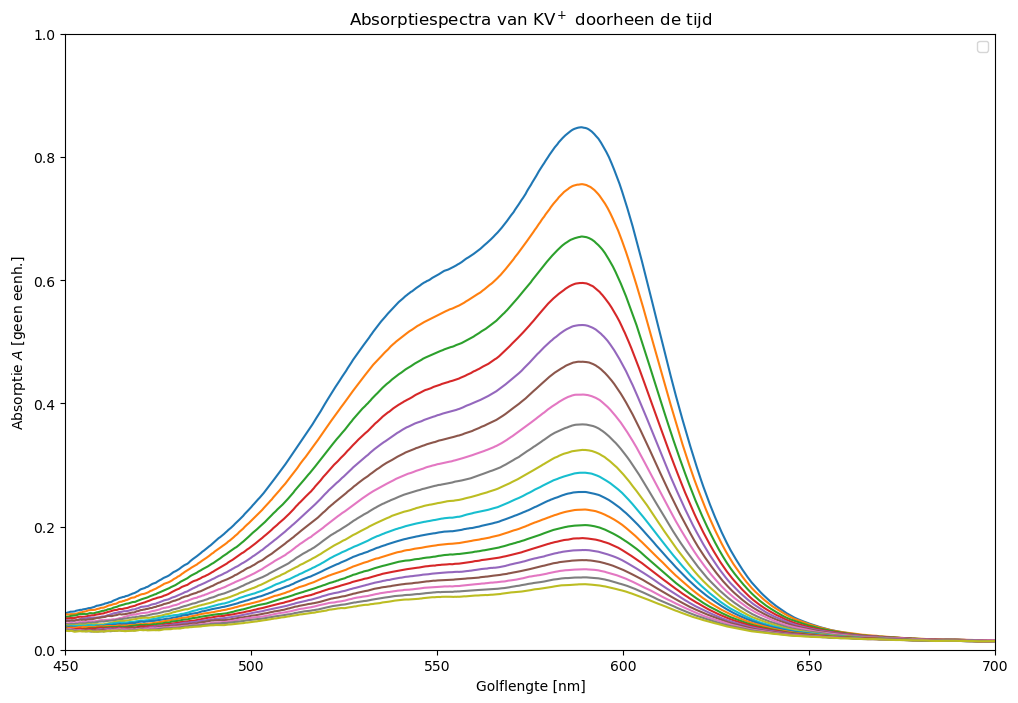

In [14]:
plt.figure(figsize=(12, 8))
t = np.linspace(0, 360, 19)
# Loop door de lijst met DataFrames en plot elk spectrum
for i, spectrum_df in enumerate(alle_res):
    # Gebruik de golflengte voor de x-as en de absorptie voor de y-as
    plt.plot(spectrum_df["lambda"], spectrum_df["abs"])

# Voeg labels en een titel toe aan de grafiek
plt.xlabel(r"Golflengte [nm]")
plt.ylabel(r"Absorptie $A$ [geen eenh.]")
plt.title(r"Absorptiespectra van KV$^+$ doorheen de tijd")

# Voeg een legenda toe om de verschillende metingen te identificeren
plt.legend()

# Voeg een grid toe voor betere leesbaarheid
plt.xlim(450, 700)
plt.ylim(0, 1)
# Toon de grafiek
plt.show()